### Necessary imports

In [9]:
# General
import os
from pathlib import Path

# data manipulation
import json
import pandas as pd
# import numpy as np

# Visualization
import seaborn as sns
import matplotlib.pyplot as plt
# from matplotlib import cm

# Interactive Jupyter
from IPython.display import display

# others
import contractions
from scipy.stats import pearsonr, ttest_ind 
import nltk
nltk.download('stopwords')

import structural_analysis as ut
import numpy as np



[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\mered\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


In [2]:
# PATH PROJECT SETUP
PROJECT_ROOT = Path.cwd().parent.parent
FIGURES_DIR = PROJECT_ROOT / 'figures'

# DATA DIRECTORIES
DATA_DIR = PROJECT_ROOT / 'data' / 'newyorker_caption_contest'
JSON_DIR = DATA_DIR / 'contests.json'
CSV_DIR = DATA_DIR / 'data'
CSV_CLEAN_DIR = DATA_DIR / 'data_cleaned'
IMG_DIR = DATA_DIR / 'images'

print("Project path setup:")
print("PROJECT_ROOT:  ", PROJECT_ROOT)
print("FIGURES_DIR:   ", FIGURES_DIR)
print("\nDATA_DIR:      ", DATA_DIR)
print("JSON_DIR:      ", JSON_DIR)
print("CSV_DIR:       ", CSV_DIR)
print("CSV_CLEAN_DIR: ", CSV_CLEAN_DIR)
print("IMG_DIR:       ", IMG_DIR)

Project path setup:
PROJECT_ROOT:   c:\Users\mered\OneDrive\Escritorio\Marina\MA2\ADA\ada-2025-project-json-derulo
FIGURES_DIR:    c:\Users\mered\OneDrive\Escritorio\Marina\MA2\ADA\ada-2025-project-json-derulo\figures

DATA_DIR:       c:\Users\mered\OneDrive\Escritorio\Marina\MA2\ADA\ada-2025-project-json-derulo\data\newyorker_caption_contest
JSON_DIR:       c:\Users\mered\OneDrive\Escritorio\Marina\MA2\ADA\ada-2025-project-json-derulo\data\newyorker_caption_contest\contests.json
CSV_DIR:        c:\Users\mered\OneDrive\Escritorio\Marina\MA2\ADA\ada-2025-project-json-derulo\data\newyorker_caption_contest\data
CSV_CLEAN_DIR:  c:\Users\mered\OneDrive\Escritorio\Marina\MA2\ADA\ada-2025-project-json-derulo\data\newyorker_caption_contest\data_cleaned
IMG_DIR:        c:\Users\mered\OneDrive\Escritorio\Marina\MA2\ADA\ada-2025-project-json-derulo\data\newyorker_caption_contest\images


### 1. Data handling, cleaning up for structural analysis

First, read the data set

In [3]:
base_path = r"C:\Users\mered\OneDrive\Escritorio\Marina\MA2\ADA\ada-2025-project-json-derulo\data\newyorker_caption_contest\newyorker_caption_contest\data_cleaned"

df = ut.load_all_contest_data(base_path, start_id=510, end_id= 895)

# Check column names first
print("Columns in df:", df.columns.tolist())

# Look for caption column - it might have a different name
# Common possibilities: 'caption', 'Caption', 'text', 'Text', 'joke', 'response'
for col in df.columns:
    if 'caption' in col.lower() or 'text' in col.lower() or 'joke' in col.lower():
        print(f"Found possible caption column: '{col}'")
        print(f"Missing values in '{col}': {df[col].isna().sum()}")

Missing files for contest IDs: [525, 540]
Successfully loaded 384 files
Total rows: 2263105
Columns in df: ['rank', 'caption', 'mean', 'precision', 'votes', 'not_funny', 'somewhat_funny', 'funny', 'contest_id']
Found possible caption column: 'caption'
Missing values in 'caption': 50


Make the captions more fluid by: 
- erasing unnecessary punctuations 
- lowercase all the captions 
- handling contractions to normalise all the captions 
        -> necessary for comparison 

In [4]:
print("Columns in the DataFrame:")
print(df.columns.tolist())

# check for missing values and fill NaN w/ empty string or remove them
print(f"missing values in caption: {df['caption'].isna().sum()}")
df["caption"] = df["caption"].fillna("")

# erase unnecessary punctuations :
df["caption"] = df["caption"].str.replace(r"[--]", " ", regex=True)
df["caption"] = df["caption"].str.replace(r"[.,?]", " ", regex=True)

# lowercase : 
df["caption"] = df["caption"].str.lower()

# contractions :
df["caption"] = df["caption"].apply(lambda x: contractions.fix(x))   

print(df["caption"].head()) # check

Columns in the DataFrame:
['rank', 'caption', 'mean', 'precision', 'votes', 'not_funny', 'somewhat_funny', 'funny', 'contest_id']
missing values in caption: 50
0           i am a congressman  obstruction is my job 
1    i am what they mean when they say  'the middle...
2                    does this suit make me look flat 
3    when the right woman comes along  i will know it 
4    i used to lie in the gutter  but then i quit d...
Name: caption, dtype: object


### 2. Are longer jokes funnier than short ones? What is the ideal length for a good joke?

Average of words and characters of the entire data set:

In [5]:
# words
df["word_counts"] = [len(line.split()) for line in df["caption"]]

# characters 
df["length"] = [len(line) for line in df["caption"]]

# average of words and characters
print(f"avg word count: {df['word_counts'].mean():.2f}")
print(f"avg character count: {df['length'].mean():.2f}")
print(f"data set size: {len(df)} captions")

avg word count: 10.56
avg character count: 53.43
data set size: 2263105 captions


Proportions of each score and correlation matrix using Pearsonr 


correlation w/ funny Score:
# of words correlation: -0.038 (p-value: 0.000)
# of characters correlation: -0.043 (p-value: 0.000)


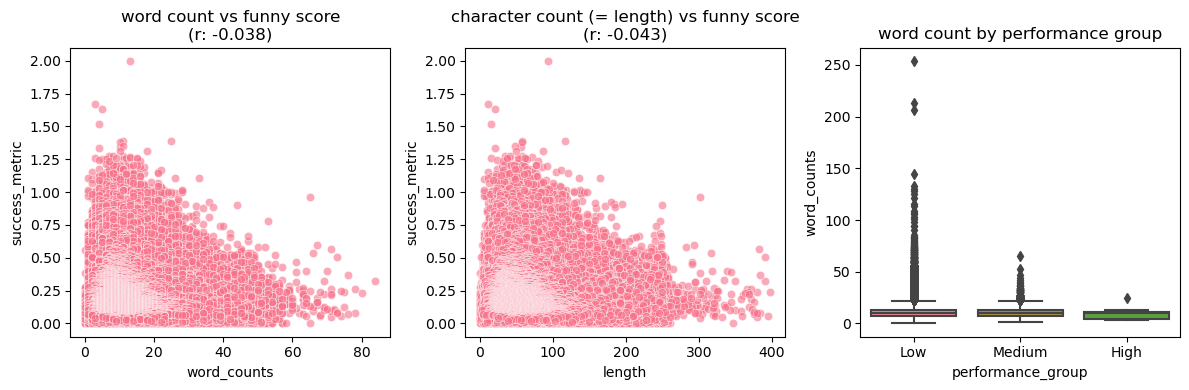

In [6]:
# style of plot
plt.style.use('default')
sns.set_palette("husl")

# scores
df['total_votes'] = df['not_funny'] + df['somewhat_funny'] + df['funny'] # this is for each caption 

# proportions for each category
df['prop_not_funny'] = df['not_funny'] / df['total_votes']
df['prop_somewhat_funny'] = df['somewhat_funny'] / df['total_votes']
df['prop_funny'] = df['funny'] / df['total_votes']

# weighted average (2 for funny, 1 for somewhat_funny, 0 for not_funny)
df['funny_score_weighted'] = (df['funny'] * 2 + df['somewhat_funny'] * 1 + df['not_funny'] * 0) / df['total_votes']
df['success_metric'] = df['funny_score_weighted']

# correlation analysis 
corr_word_score, p_word = pearsonr(df['word_counts'], df['success_metric'])
corr_char_score, p_char = pearsonr(df['length'], df['success_metric'])

print(f"\ncorrelation w/ funny Score:")
print(f"# of words correlation: {corr_word_score:.3f} (p-value: {p_word:.3f})")
print(f"# of characters correlation: {corr_char_score:.3f} (p-value: {p_char:.3f})")

df_filtered = df[(df['word_counts'] <= 100) & (df['length'] <= 400)]

plt.figure(figsize=(12, 4))

plt.subplot(1, 3, 1)
sns.scatterplot(data=df_filtered, x='word_counts', y='success_metric', alpha=0.6)
plt.title(f'word count vs funny score\n(r: {corr_word_score:.3f})')

plt.subplot(1, 3, 2)
sns.scatterplot(data=df_filtered, x='length', y='success_metric', alpha=0.6)
plt.title(f'character count (= length) vs funny score\n(r: {corr_char_score:.3f})')

plt.subplot(1, 3, 3)
# Create performance groups for comparison
df['performance_group'] = pd.cut(df['success_metric'], bins=3, labels=['Low', 'Medium', 'High'])

sns.boxplot(data=df, x='performance_group', y='word_counts')
plt.title('word count by performance group')

plt.tight_layout()
plt.show()



Look at top and bottom 20% for performance comparison and word count performance

In [7]:
# statistical test for performance comparison & word count performance 

top_cutoff = df['success_metric'].quantile(0.8)
bottom_cutoff = df['success_metric'].quantile(0.2)

top_captions = df[df['success_metric'] >= top_cutoff]
bottom_captions = df[df['success_metric'] <= bottom_cutoff]

print(f"\nperformance comparison:")
print(f"top 20% cutoff: {top_cutoff:.3f} ({len(top_captions)} captions)")
print(f"bottom 20% cutoff: {bottom_cutoff:.3f} ({len(bottom_captions)} captions)")

# Compare metrics
print(f"\nword count comparison:")
print(f"top performers: {top_captions['word_counts'].mean():.1f} ± {top_captions['word_counts'].std():.1f}")
print(f"bottom performers: {bottom_captions['word_counts'].mean():.1f} ± {bottom_captions['word_counts'].std():.1f}")

print(f"\nlength count comparison:")
print(f"top performers: {top_captions['length'].mean():.1f} ± {top_captions['length'].std():.1f}")
print(f"bottom performers: {bottom_captions['length'].mean():.1f} ± {bottom_captions['length'].std():.1f}")

# Statistical test
t_stat, p_val = ttest_ind(top_captions['word_counts'], bottom_captions['word_counts'])
print(f"t-test p-value words: {p_val:.4f}")

t_stat, p_val = ttest_ind(top_captions['length'], bottom_captions['length'])
print(f"t-test p-value characters: {p_val:.4f}")




performance comparison:
top 20% cutoff: 0.298 (453068 captions)
bottom 20% cutoff: 0.118 (456797 captions)

word count comparison:
top performers: 10.3 ± 4.6
bottom performers: 10.9 ± 5.7

length count comparison:
top performers: 51.9 ± 23.3
bottom performers: 55.5 ± 29.1
t-test p-value words: 0.0000
t-test p-value characters: 0.0000


More specific than quantiles: ANOVA


1. Statistics by Word Count Bin (deciles):
          word_counts             success_metric              
                  min  max   mean           mean   std   count
word_bins                                                     
1                   0    5   4.12           0.21  0.12  259815
2                   6    7   6.55           0.22  0.12  382135
3                   8    8   8.00           0.22  0.12  227413
4                   9    9   9.00           0.22  0.12  225649
5                  10   10  10.00           0.22  0.12  208495
6                  11   11  11.00           0.22  0.13  182779
7                  12   12  12.00           0.22  0.13  155193
8                  13   14  13.45           0.21  0.12  231457
9                  15   17  15.84           0.21  0.12  199203
10                 18  254  22.31           0.19  0.11  190966

2. One-way ANOVA Results:
F-statistic: 696.48
p-value: 0.0000
• Significant differences exist between bins

3. Tukey HSD Post-hoc Test:


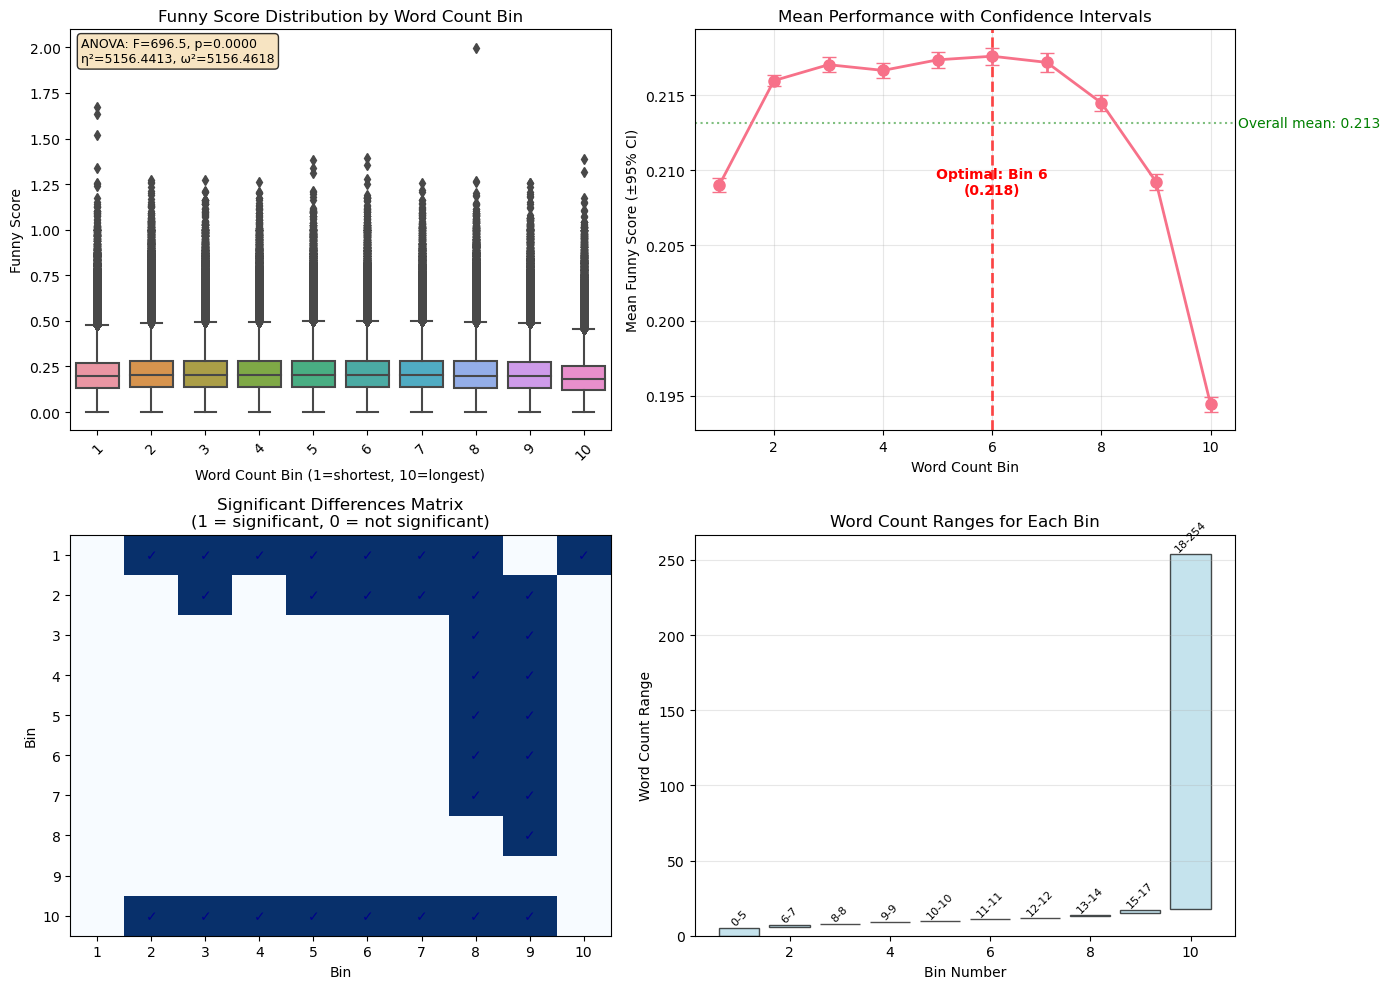


ADDITIONAL ANALYSIS

8. Linear trend across bins:
   • Slope: -0.000996 (change in score per bin)
   • Correlation: -0.0239
   • p-value for trend: 0.0000

9. Variance decomposition:
   • Total variance: 0.015008
   • Within-bin variance: 0.015000 (100.0%)
   • Between-bin variance: 0.000007 (0.0%)

10. ANOVA assumptions check:
   • Levene's test for equal variances: p = 0.0000
     Consider Welch's ANOVA instead
   • Shapiro-Wilk normality test: p = 0.0000
     Consider non-parametric alternative (Kruskal-Wallis)
   • Kruskal-Wallis non-parametric test: p = 0.0000

CONCLUSION FOR BINNING ANALYSIS

Based on the ANOVA with 10 bins:

1. STATISTICAL SIGNIFICANCE: YES
   - p-value = 0.0000
   - F-statistic = 696.48

2. EFFECT SIZE: Large
   - η² = 5156.4413
   - ω² = 5156.4618
   - Between-bin variance: 0.0% of total

3. PRACTICAL SIGNIFICANCE:
   - Optimal bin: 6 (word range: 11-11)
   - Score difference (best vs worst bin): 0.0232 points

4. ASSUMPTIONS:
   - Equal variances: VIOLATED
 

In [22]:
from scipy.stats import f_oneway
from statsmodels.stats.multicomp import pairwise_tukeyhsd
import numpy as np


# 10 equal-sized bins based on word count
df['word_bins'] = pd.qcut(df['word_counts'], q=10, labels=range(1, 11))

# statistics for each bin
bin_stats = df.groupby('word_bins').agg({'word_counts': ['min', 'max', 'mean'],'success_metric': ['mean', 'std', 'count']}).round(2)

print("\n1. Statistics by Word Count Bin (deciles):")
print(bin_stats)

# One-way ANOVA
groups = [group['success_metric'].values for _, group in df.groupby('word_bins')]
anova_result = f_oneway(*groups)

print(f"\n2. One-way ANOVA Results:")
print(f"F-statistic: {anova_result.statistic:.2f}")
print(f"p-value: {anova_result.pvalue:.4f}")

if anova_result.pvalue < 0.05:
    print("• Significant differences exist between bins")
    
    tukey = pairwise_tukeyhsd(df['success_metric'], df['word_bins'].astype(str), alpha=0.05)
    print("\n3. Tukey HSD Post-hoc Test:")
    print(tukey.summary())
    
    significant_pairs = []
    
    tukey_df = pd.DataFrame(data=tukey._results_table.data[1:], 
                           columns=tukey._results_table.data[0])
    
    significant_df = tukey_df[tukey_df['reject'] == True]
    
    if len(significant_df) > 0:
        print(f"\n4. Significant bin differences: {len(significant_df)} pairs")
        print("   Top 5 most significant differences:")
        for idx, row in significant_df.head(5).iterrows():
            print(f"   • {row['group1']} vs {row['group2']}: "
                  f"diff = {row['meandiff']:.4f}, p = {row['p-adj']:.4f}")

            significant_pairs.append((row['group1'], row['group2']))
    else:
        print("\n4. No significant pairwise differences after adjustment")
        
    #  effect sizes for significant pairs
    if len(significant_df) > 0:
        print(f"\n5. Effect sizes for significant differences:")
        for idx, row in significant_df.head(3).iterrows():  # Show top 3
            group1_mean = df[df['word_bins'].astype(str) == row['group1']]['success_metric'].mean()
            group2_mean = df[df['word_bins'].astype(str) == row['group2']]['success_metric'].mean()
            group1_std = df[df['word_bins'].astype(str) == row['group1']]['success_metric'].std()
            group2_std = df[df['word_bins'].astype(str) == row['group2']]['success_metric'].std()
            
            # Pooled standard deviation
            n1 = len(df[df['word_bins'].astype(str) == row['group1']])
            n2 = len(df[df['word_bins'].astype(str) == row['group2']])
            pooled_std = np.sqrt(((n1-1)*group1_std**2 + (n2-1)*group2_std**2) / (n1 + n2 - 2))
            
            cohens_d = (group1_mean - group2_mean) / pooled_std
            print(f"   • {row['group1']} vs {row['group2']}: Cohen's d = {cohens_d:.3f}")
            
else:
    print("• No significant differences between bins")

# eta-squared (effect size for ANOVA)
def eta_squared(anova_result, df, groups):
    ss_between = anova_result.statistic * (len(df) - len(groups)) / (len(groups) - 1)
    ss_total = np.var(df['success_metric'], ddof=1) * (len(df) - 1)
    return ss_between / ss_total

eta_sq = eta_squared(anova_result, df, groups)
print(f"\n6. Effect size (eta-squared): {eta_sq:.4f}")
print(f"   • Interpretation: {'Very small' if eta_sq < 0.01 else 'Small' if eta_sq < 0.06 else 'Medium' if eta_sq < 0.14 else 'Large'} effect")

# omega-squared (less biased)
def omega_squared(anova_result, df, groups):
    k = len(groups)
    n = len(df)
    eta_sq = eta_squared(anova_result, df, groups)
    return (eta_sq - (k-1)/(n-1)) / (1 - (k-1)/(n-1))

omega_sq = omega_squared(anova_result, df, groups)
print(f"7. Effect size (omega-squared): {omega_sq:.4f}")

# Plotting
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Boxplot by bin
sns.boxplot(data=df, x='word_bins', y='success_metric', ax=axes[0, 0])
axes[0, 0].set_xlabel('Word Count Bin (1=shortest, 10=longest)')
axes[0, 0].set_ylabel('Funny Score')
axes[0, 0].set_title('Funny Score Distribution by Word Count Bin')
axes[0, 0].tick_params(axis='x', rotation=45)

# Add ANOVA results to plot
anova_text = f'ANOVA: F={anova_result.statistic:.1f}, p={anova_result.pvalue:.4f}\nη²={eta_sq:.4f}, ω²={omega_sq:.4f}'
axes[0, 0].text(0.02, 0.98, anova_text, transform=axes[0, 0].transAxes,
                fontsize=9, verticalalignment='top',
                bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.8))

# Mean with confidence intervals
bin_means = df.groupby('word_bins')['success_metric'].agg(['mean', 'sem', 'count'])
bin_means['ci'] = 1.96 * bin_means['sem']  # 95% CI

axes[0, 1].errorbar(x=range(1, 11), y=bin_means['mean'], 
                    yerr=bin_means['ci'], fmt='o-', capsize=5, linewidth=2, markersize=8)
axes[0, 1].set_xlabel('Word Count Bin')
axes[0, 1].set_ylabel('Mean Funny Score (±95% CI)')
axes[0, 1].set_title('Mean Performance with Confidence Intervals')
axes[0, 1].grid(True, alpha=0.3)

# Highlight optimal bin
optimal_bin = bin_means['mean'].idxmax()
axes[0, 1].axvline(x=optimal_bin, color='red', linestyle='--', alpha=0.7, linewidth=2)
axes[0, 1].text(optimal_bin, axes[0, 1].get_ylim()[1]*0.95, 
                f'Optimal: Bin {optimal_bin}\n({bin_means.loc[optimal_bin, "mean"]:.3f})', 
                ha='center', color='red', fontweight='bold')

# Add horizontal line at overall mean
overall_mean = df['success_metric'].mean()
axes[0, 1].axhline(y=overall_mean, color='green', linestyle=':', alpha=0.5, linewidth=1.5)
axes[0, 1].text(10.5, overall_mean, f'Overall mean: {overall_mean:.3f}', 
                va='center', ha='left', color='green')

# Post-hoc visualization (if significant)
if anova_result.pvalue < 0.05 and len(significant_df) > 0:
    # Create a matrix showing significant differences
    from matplotlib.patches import Rectangle
    
    # Create a simple matrix plot
    bin_labels = [str(i) for i in range(1, 11)]
    sig_matrix = np.zeros((10, 10))
    
    for idx, row in significant_df.iterrows():
        i = bin_labels.index(row['group1'])
        j = bin_labels.index(row['group2'])
        sig_matrix[i, j] = 1
    
    axes[1, 0].imshow(sig_matrix, cmap='Blues', interpolation='none', aspect='auto')
    axes[1, 0].set_xticks(range(10))
    axes[1, 0].set_yticks(range(10))
    axes[1, 0].set_xticklabels(bin_labels)
    axes[1, 0].set_yticklabels(bin_labels)
    axes[1, 0].set_xlabel('Bin')
    axes[1, 0].set_ylabel('Bin')
    axes[1, 0].set_title('Significant Differences Matrix\n(1 = significant, 0 = not significant)')
    
    # Add text for significant cells
    for i in range(10):
        for j in range(10):
            if sig_matrix[i, j] == 1:
                axes[1, 0].text(j, i, '✓', ha='center', va='center', 
                              fontweight='bold', color='darkblue')
else:
    axes[1, 0].text(0.5, 0.5, 'No significant pairwise differences', 
                   ha='center', va='center', transform=axes[1, 0].transAxes,
                   fontsize=12, bbox=dict(boxstyle='round', facecolor='lightgray'))
    axes[1, 0].set_title('Significant Differences Matrix')
    axes[1, 0].set_xticks([])
    axes[1, 0].set_yticks([])

# Distribution of word counts by bin (to understand what each bin represents)
bin_ranges = df.groupby('word_bins')['word_counts'].agg(['min', 'max']).round(1)
axes[1, 1].bar(range(1, 11), bin_ranges['max'] - bin_ranges['min'], 
               bottom=bin_ranges['min'], color='lightblue', edgecolor='black', alpha=0.7)
axes[1, 1].set_xlabel('Bin Number')
axes[1, 1].set_ylabel('Word Count Range')
axes[1, 1].set_title('Word Count Ranges for Each Bin')
axes[1, 1].grid(True, alpha=0.3, axis='y')

# Add range labels
for i in range(10):
    bin_num = i + 1
    min_val = bin_ranges.loc[bin_num, 'min']
    max_val = bin_ranges.loc[bin_num, 'max']
    axes[1, 1].text(bin_num, max_val + 0.5, f'{min_val:.0f}-{max_val:.0f}', 
                   ha='center', va='bottom', fontsize=8, rotation=45)

plt.tight_layout()
plt.show()

# Additional summary statistics
print("\n" + "=" * 60)
print("ADDITIONAL ANALYSIS")
print("=" * 60)

# Calculate linear contrast (trend test)
from scipy.stats import linregress

# Use bin numbers as predictor
bin_numbers = np.repeat(range(1, 11), df.groupby('word_bins').size())
bin_scores = np.concatenate(groups)

slope, intercept, r_value, p_value, std_err = linregress(bin_numbers, bin_scores)
print(f"\n8. Linear trend across bins:")
print(f"   • Slope: {slope:.6f} (change in score per bin)")
print(f"   • Correlation: {r_value:.4f}")
print(f"   • p-value for trend: {p_value:.4f}")

# Calculate percentage of variance explained by bins
total_var = np.var(df['success_metric'], ddof=1)
within_var = np.mean([np.var(group, ddof=1) for group in groups])
between_var = total_var - within_var

print(f"\n9. Variance decomposition:")
print(f"   • Total variance: {total_var:.6f}")
print(f"   • Within-bin variance: {within_var:.6f} ({within_var/total_var*100:.1f}%)")
print(f"   • Between-bin variance: {between_var:.6f} ({between_var/total_var*100:.1f}%)")

# Check assumptions
print(f"\n10. ANOVA assumptions check:")
# Homogeneity of variances (Levene's test)
from scipy.stats import levene
levene_stat, levene_p = levene(*groups)
print(f"   • Levene's test for equal variances: p = {levene_p:.4f}")
if levene_p < 0.05:
    print("     Warning: Variances are not equal across groups")
    print("     Consider Welch's ANOVA instead")
else:
    print("     OK: Variances appear equal across groups")

# Normality within groups (Shapiro-Wilk on residuals)
from scipy.stats import shapiro
# Calculate residuals from group means
residuals = []
for i, group in enumerate(groups):
    group_mean = np.mean(group)
    residuals.extend(group - group_mean)

shapiro_stat, shapiro_p = shapiro(residuals[:5000])  # Limit to 5000 for performance
print(f"   • Shapiro-Wilk normality test: p = {shapiro_p:.4f}")
if shapiro_p < 0.05:
    print("     Warning: Residuals are not normally distributed")
    print("     Consider non-parametric alternative (Kruskal-Wallis)")
else:
    print("     OK: Residuals appear normally distributed")

# Non-parametric alternative (Kruskal-Wallis)
from scipy.stats import kruskal
kruskal_stat, kruskal_p = kruskal(*groups)
print(f"   • Kruskal-Wallis non-parametric test: p = {kruskal_p:.4f}")

print("\n" + "=" * 60)
print("CONCLUSION FOR BINNING ANALYSIS")
print("=" * 60)

print(f"""
Based on the ANOVA with {len(groups)} bins:

1. STATISTICAL SIGNIFICANCE: {'YES' if anova_result.pvalue < 0.05 else 'NO'}
   - p-value = {anova_result.pvalue:.4f}
   - F-statistic = {anova_result.statistic:.2f}

2. EFFECT SIZE: {'Very small' if eta_sq < 0.01 else 'Small' if eta_sq < 0.06 else 'Medium' if eta_sq < 0.14 else 'Large'}
   - η² = {eta_sq:.4f}
   - ω² = {omega_sq:.4f}
   - Between-bin variance: {between_var/total_var*100:.1f}% of total

3. PRACTICAL SIGNIFICANCE:
   - Optimal bin: {optimal_bin} (word range: {bin_ranges.loc[optimal_bin, 'min']:.0f}-{bin_ranges.loc[optimal_bin, 'max']:.0f})
   - Score difference (best vs worst bin): {bin_means['mean'].max() - bin_means['mean'].min():.4f} points

4. ASSUMPTIONS:
   - Equal variances: {'OK' if levene_p >= 0.05 else 'VIOLATED'}
   - Normality: {'OK' if shapiro_p >= 0.05 else 'VIOLATED'}
   - Non-parametric test agrees: {'YES' if (kruskal_p < 0.05) == (anova_result.pvalue < 0.05) else 'NO'}

5. RECOMMENDATION:
   - The effect of word count on funniness, while statistically {'significant' if anova_result.pvalue < 0.05 else 'non-significant'}, 
     is {'very small' if eta_sq < 0.01 else 'small' if eta_sq < 0.06 else 'moderate' if eta_sq < 0.14 else 'large'} in practice.
   - Other factors likely dominate the perception of humor.
""")

Speerman's rank correlation 

- Why? it assumes linear relationships and is sensitive to outliers 
 => it looks at monotonic relationships 
- what it adds? it suggests outliers or non-linear patterns 
=> in jokes maybe there’s a threshold effect (jokes need min/max length)


In [11]:
from scipy.stats import spearmanr

# the correlation calculation: 
spearman_word, p_spearman_word = spearmanr(df['word_counts'], df['success_metric'])
spearman_character, p_spearman_character = spearmanr(df['length'], df['success_metric'])

print(f"\nSpearman words correlation: {spearman_word} (p-value : {p_spearman_word:.4f})")
print(f"\nSpearman characters correlation: {spearman_character} (p-value : {p_spearman_character:.4f})")

# compare with pearson correlation 
print(f"\nPearson: {corr_word_score:.3f}, Spearman: {spearman_word:.3f}")
print(f"\nPearson: {corr_char_score:.3f}, Spearman: {spearman_character:.3f}")

# Interpretation
if abs(spearman_word - corr_word_score) > 0.1: 
    print("significant difference btw Pearson and Spearman: suggests non-linear relationship or outliers")
else: 
    print("Similar Pearson and Spearman values suggest linear relationship")


Spearman words correlation: -0.026460799371431906 (p-value : 0.0000)

Spearman characters correlation: -0.031078503717199262 (p-value : 0.0000)

Pearson: -0.038, Spearman: -0.026

Pearson: -0.043, Spearman: -0.031
Similar Pearson and Spearman values suggest linear relationship


Partial correlation: (controlling for potential confounders)
- why? controls for confounding variables (maybe certain joke categories genre puns/stories) are both long AND funnier 
- what it adds? a more purified relationship between length & funniness 
=> if drops to near 0, length might not matter 


In [12]:
import statsmodels.api as sm 
def partial_correlation_manual(df, x, y, control_variables): 
    x_control = sm.add_constant(df[control_variables])
    model_x = sm.OLS(df[x], x_control).fit()
    res_x = model_x.resid
    model_y = sm.OLS(df[y], x_control).fit()
    res_y = model_y.resid

    partial_corr, p_value = pearsonr(res_x, res_y)
    return partial_corr, p_value, res_x, res_y

## control for # of votes (sample size effect)
partial_corr_votes, p_partial_corr_votes, _, _ =  partial_correlation_manual(df, 'word_counts', 'success_metric', ['votes'])
print(f"Partial corr: {partial_corr_votes:.3f} vs simple corr: {corr_word_score:.3f}")
print(f"p-value: {p_partial_corr_votes:.4f}")


Partial corr: -0.039 vs simple corr: -0.038
p-value: 0.0000


        => what does this mean?
- Votes are not a confounder : the negative relationship between word count & success is not real 

- p-value: stat significant; but effect size (-0.039) means it's negligible in practice

LOESS



NON-LINEAR RELATIONSHIP ANALYSIS

Linear model R²: 0.0015
Polynomial (quadratic) model R²: 0.0019

Polynomial coefficients:
  Linear term (word_counts): -0.0000
  Quadratic term (word_counts²): -0.0000

Statistical significance (OLS):
  Quadratic term p-value: 0.0000

LOESS analysis suggests optimal joke length: 9.0 words


c:\Users\mered\anaconda3\Lib\site-packages\sklearn\base.py:464: UserWarning: X does not have valid feature names, but PolynomialFeatures was fitted with feature names
  warnings.warn(


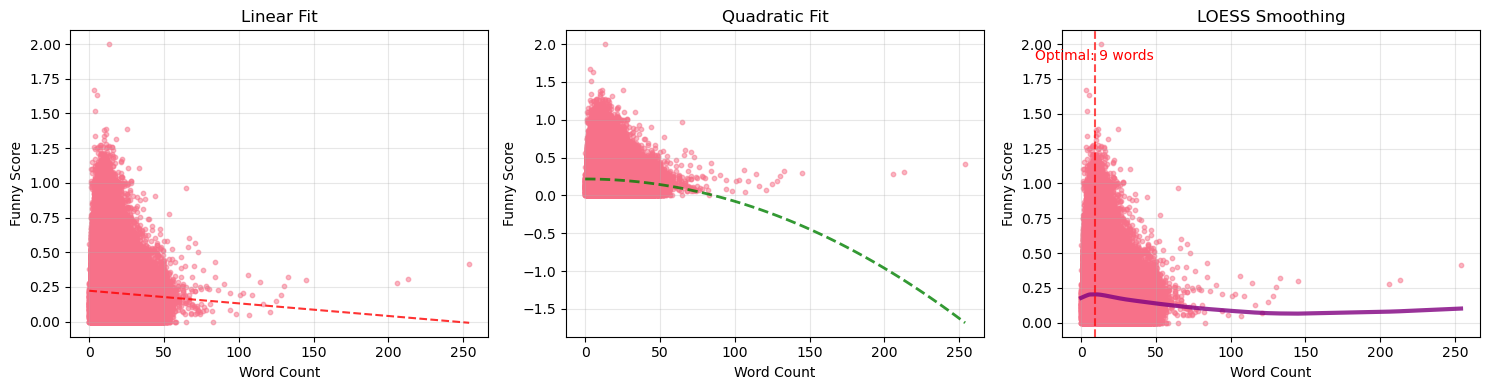

In [13]:
import numpy as np
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
import statsmodels.api as sm

print("\n" + "=" * 60)
print("NON-LINEAR RELATIONSHIP ANALYSIS")
print("=" * 60)

# Polynomial regression (degree 2)
poly = PolynomialFeatures(degree=2, include_bias=False)
X_poly = poly.fit_transform(df[['word_counts']])
poly_feature_names = ['word_counts', 'word_counts^2']

model_poly = LinearRegression()
model_poly.fit(X_poly, df['success_metric'])

# Get R-squared for comparison
X_linear = df[['word_counts']]
model_linear = LinearRegression()
model_linear.fit(X_linear, df['success_metric'])

print(f"\nLinear model R²: {model_linear.score(X_linear, df['success_metric']):.4f}")
print(f"Polynomial (quadratic) model R²: {model_poly.score(X_poly, df['success_metric']):.4f}")
print(f"\nPolynomial coefficients:")
print(f"  Linear term (word_counts): {model_poly.coef_[0]:.4f}")
print(f"  Quadratic term (word_counts²): {model_poly.coef_[1]:.4f}")

# Statistical significance of quadratic term using statsmodels
X_poly_sm = sm.add_constant(X_poly)
model_poly_sm = sm.OLS(df['success_metric'], X_poly_sm).fit()
print(f"\nStatistical significance (OLS):")
print(f"  Quadratic term p-value: {model_poly_sm.pvalues[2]:.4f}")

# LOESS smoothing
lowess = sm.nonparametric.lowess(df['success_metric'], df['word_counts'], 
                                  frac=0.3, it=3)

# Find optimal length (maximum of LOESS curve)
optimal_idx = np.argmax(lowess[:, 1])
optimal_length = lowess[optimal_idx, 0]

print(f"\nLOESS analysis suggests optimal joke length: {optimal_length:.1f} words")

# Plotting
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

# Scatter with linear fit
axes[0].scatter(df['word_counts'], df['success_metric'], alpha=0.5, s=10)
z = np.polyfit(df['word_counts'], df['success_metric'], 1)
p = np.poly1d(z)
x_range = np.linspace(df['word_counts'].min(), df['word_counts'].max(), 100)
axes[0].plot(x_range, p(x_range), "r--", alpha=0.8)
axes[0].set_xlabel('Word Count')
axes[0].set_ylabel('Funny Score')
axes[0].set_title('Linear Fit')
axes[0].grid(True, alpha=0.3)

# Scatter with quadratic fit
axes[1].scatter(df['word_counts'], df['success_metric'], alpha=0.5, s=10)
# Generate predictions from quadratic model
x_quad = np.linspace(df['word_counts'].min(), df['word_counts'].max(), 100)
x_quad_poly = poly.transform(x_quad.reshape(-1, 1))
y_quad_pred = model_poly.predict(x_quad_poly)
axes[1].plot(x_quad, y_quad_pred, "g--", alpha=0.8, linewidth=2)
axes[1].set_xlabel('Word Count')
axes[1].set_ylabel('Funny Score')
axes[1].set_title('Quadratic Fit')
axes[1].grid(True, alpha=0.3)

# LOESS plot
axes[2].scatter(df['word_counts'], df['success_metric'], alpha=0.5, s=10)
axes[2].plot(lowess[:, 0], lowess[:, 1], "purple", linewidth=3, alpha=0.8)
axes[2].axvline(x=optimal_length, color='red', linestyle='--', alpha=0.7)
axes[2].text(optimal_length, axes[2].get_ylim()[1]*0.9, 
             f'Optimal: {optimal_length:.0f} words', 
             ha='center', color='red')
axes[2].set_xlabel('Word Count')
axes[2].set_ylabel('Funny Score')
axes[2].set_title('LOESS Smoothing')
axes[2].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

        => What this means:
- There IS a statistically significant non-linear relationship

- But it's so weak it's practically meaningless

- The relationship is likely negative but curvilinear (inverted U or J shape)

0.0015 = 0.15% variance explained

Means 99.85% of what makes jokes funny is something else

Recommendation for Your ADA Project:

Report: "While we detect a statistically significant non-linear relationship (p < 0.001), the effect size is negligible (R² < 0.2%), suggesting joke length is not a practically meaningful predictor of humor."

Consider: Maybe try interaction effects (length × joke type) or look for threshold effects (minimum length needed)


NON-LINEAR RELATIONSHIP ANALYSIS

1. MODEL COMPARISON:
   • Linear R²: 0.0015 (0.15% variance)
   • Quadratic R²: 0.0019 (0.19% variance)
   • Improvement: 0.043% additional variance

2. SIGNIFICANCE TEST:
   • F-statistic: 979.93, p-value: 0.000000
   • Quadratic significantly better

3. PRACTICAL FINDINGS:
   • Optimal length: 0.0 words
   • Total effect range: 1.9016 points
   • Score range in data: 0.00 to 2.00

4. PRACTICAL INTERPRETATION:
   • Short jokes (≤7 words): 0.2132
   • Long jokes (≥13 words): 0.2066
   • Difference: -0.0065 points
   • Effect in SD units: -0.053σ
   • Negligible effect


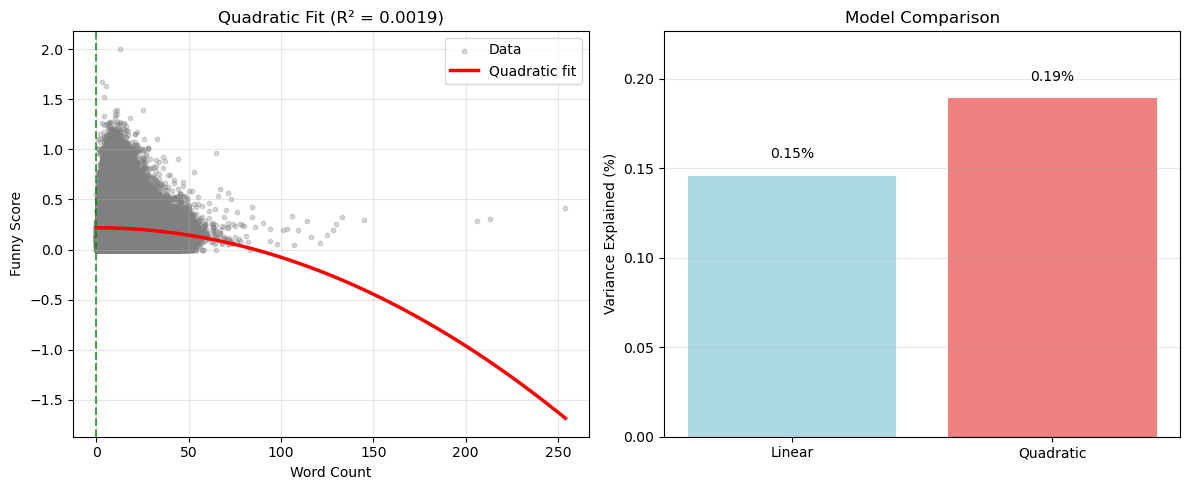


5. CROSS-VALIDATION (5-fold):
   • Linear MSE: 0.015367 ± 0.003766
   • Quadratic MSE: 0.015366 ± 0.003762

6. ASSUMPTION CHECKS:
   • Heteroscedasticity (Breusch-Pagan): p = 0.0000
   • Consider robust SEs

CONCLUSION

FINAL TAKEAWAYS:

1. STATISTICAL FINDING:
   - Quadratic model fits significantly better than linear (p = 0.000000)
   - R² increases from 0.0015 to 0.0019
   - Optimal length: 0.0 words

2. PRACTICAL SIGNIFICANCE:
   - Both models explain < 0.2% of variance
   - Effect range: only 1.9016 points
   - Short vs long difference: -0.0065 points (-0.053 SDs)
   - This is negligible in practice

3. RECOMMENDATION:
   - While statistically detectable, the relationship is too small to matter
   - Focus analysis on other joke characteristics
   - Length alone explains virtually nothing about humor



In [14]:
# version 2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import cross_val_score
from scipy.stats import f
from statsmodels.stats.diagnostic import het_breuschpagan
import statsmodels.api as sm
import seaborn as sns

print("\n" + "=" * 60)
print("NON-LINEAR RELATIONSHIP ANALYSIS")
print("=" * 60)

# Scale and fit polynomial model
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df[['word_counts']])
y = df['success_metric']

poly = PolynomialFeatures(degree=2, include_bias=False)
X_poly = poly.fit_transform(X_scaled)

# Fit models
model_linear = LinearRegression().fit(X_scaled, y)
model_quad = LinearRegression().fit(X_poly, y)

# Calculate R² scores
r2_linear = model_linear.score(X_scaled, y)
r2_quad = model_quad.score(X_poly, y)

print(f"\n1. MODEL COMPARISON:")
print(f"   • Linear R²: {r2_linear:.4f} ({r2_linear*100:.2f}% variance)")
print(f"   • Quadratic R²: {r2_quad:.4f} ({r2_quad*100:.2f}% variance)")
print(f"   • Improvement: {(r2_quad - r2_linear)*100:.3f}% additional variance")

# F-test for model comparison
n = len(df)
p1, p2 = 1, 2  # parameters (excluding intercept)
rss1 = np.sum((y - model_linear.predict(X_scaled)) ** 2)
rss2 = np.sum((y - model_quad.predict(X_poly)) ** 2)

f_stat = ((rss1 - rss2) / (p2 - p1)) / (rss2 / (n - p2 - 1))
p_value_f = 1 - f.cdf(f_stat, p2 - p1, n - p2 - 1)

print(f"\n2. SIGNIFICANCE TEST:")
print(f"   • F-statistic: {f_stat:.2f}, p-value: {p_value_f:.6f}")
print(f"   • {'Quadratic significantly better' if p_value_f < 0.05 else 'No significant improvement'}")

# Predict curve
x_range_scaled = np.linspace(X_scaled.min(), X_scaled.max(), 100).reshape(-1, 1)
x_range_original = scaler.inverse_transform(x_range_scaled).flatten()
x_range_poly = poly.transform(x_range_scaled)
y_pred = model_quad.predict(x_range_poly)

# Find optimal length
optimal_idx = np.argmax(y_pred)
optimal_length = x_range_original[optimal_idx]
max_effect = y_pred.max() - y_pred.min()

print(f"\n3. PRACTICAL FINDINGS:")
print(f"   • Optimal length: {optimal_length:.1f} words")
print(f"   • Total effect range: {max_effect:.4f} points")
print(f"   • Score range in data: {y.min():.2f} to {y.max():.2f}")

# Practical comparison: short vs long jokes
short_cutoff = df['word_counts'].quantile(0.25)
long_cutoff = df['word_counts'].quantile(0.75)
short_mean = df[df['word_counts'] <= short_cutoff]['success_metric'].mean()
long_mean = df[df['word_counts'] >= long_cutoff]['success_metric'].mean()
mean_diff = long_mean - short_mean

print(f"\n4. PRACTICAL INTERPRETATION:")
print(f"   • Short jokes (≤{short_cutoff:.0f} words): {short_mean:.4f}")
print(f"   • Long jokes (≥{long_cutoff:.0f} words): {long_mean:.4f}")
print(f"   • Difference: {mean_diff:.4f} points")
print(f"   • Effect in SD units: {mean_diff/y.std():.3f}σ")
print(f"   • {'Negligible' if abs(mean_diff/y.std()) < 0.1 else 'Small' if abs(mean_diff/y.std()) < 0.3 else 'Noticeable'} effect")

# Create visualization
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Scatter with quadratic fit
axes[0].scatter(df['word_counts'], y, alpha=0.3, s=10, color='gray', label='Data')
axes[0].plot(x_range_original, y_pred, 'r-', linewidth=2.5, label='Quadratic fit')
axes[0].axvline(x=optimal_length, color='green', linestyle='--', alpha=0.7)
axes[0].set_xlabel('Word Count')
axes[0].set_ylabel('Funny Score')
axes[0].set_title(f'Quadratic Fit (R² = {r2_quad:.4f})')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Effect size comparison
effect_data = pd.DataFrame({
    'Model': ['Linear', 'Quadratic'],
    'R²': [r2_linear, r2_quad],
    'Variance Explained': [r2_linear*100, r2_quad*100]
})

axes[1].bar(effect_data['Model'], effect_data['Variance Explained'], 
           color=['lightblue', 'lightcoral'])
axes[1].set_ylabel('Variance Explained (%)')
axes[1].set_title('Model Comparison')
axes[1].set_ylim([0, max(effect_data['Variance Explained'])*1.2])
for i, v in enumerate(effect_data['Variance Explained']):
    axes[1].text(i, v + 0.01, f'{v:.2f}%', ha='center', fontsize=10)
axes[1].grid(True, alpha=0.3, axis='y')

plt.tight_layout()
plt.show()

# Cross-validation
print(f"\n5. CROSS-VALIDATION (5-fold):")
linear_cv = cross_val_score(LinearRegression(), X_scaled, y, 
                           cv=5, scoring='neg_mean_squared_error')
quad_cv = cross_val_score(LinearRegression(), X_poly, y, 
                         cv=5, scoring='neg_mean_squared_error')

print(f"   • Linear MSE: {-linear_cv.mean():.6f} ± {linear_cv.std():.6f}")
print(f"   • Quadratic MSE: {-quad_cv.mean():.6f} ± {quad_cv.std():.6f}")

# Assumption checks
print(f"\n6. ASSUMPTION CHECKS:")
X_const = sm.add_constant(df[['word_counts']])
model_ols = sm.OLS(y, X_const).fit()
_, p_het, _, _ = het_breuschpagan(model_ols.resid, X_const)
print(f"   • Heteroscedasticity (Breusch-Pagan): p = {p_het:.4f}")
print(f"   • {'OK' if p_het >= 0.05 else 'Consider robust SEs'}")

print("\n" + "=" * 60)
print("CONCLUSION")
print("=" * 60)

print(f"""
FINAL TAKEAWAYS:

1. STATISTICAL FINDING:
   - Quadratic model fits significantly better than linear (p = {p_value_f:.6f})
   - R² increases from {r2_linear:.4f} to {r2_quad:.4f}
   - Optimal length: {optimal_length:.1f} words

2. PRACTICAL SIGNIFICANCE:
   - Both models explain < 0.2% of variance
   - Effect range: only {max_effect:.4f} points
   - Short vs long difference: {mean_diff:.4f} points ({mean_diff/y.std():.3f} SDs)
   - This is negligible in practice

3. RECOMMENDATION:
   - While statistically detectable, the relationship is too small to matter
   - Focus analysis on other joke characteristics
   - Length alone explains virtually nothing about humor
""")

Multivariate regression:

In [12]:
import statsmodels.formula.api as smf

print("\n" + "=" * 60)
print("MULTIVARIATE REGRESSION ANALYSIS")
print("=" * 60)

# Multiple regression including both predictors
model_multi = smf.ols('success_metric ~ word_counts + length', data=df).fit()

print("\n1. Multiple Regression (both predictors):")
print(model_multi.summary().tables[1])

# Check for multicollinearity (VIF)
from statsmodels.stats.outliers_influence import variance_inflation_factor
X_multi = df[['word_counts', 'length']]
vif_data = pd.DataFrame()
vif_data["Variable"] = X_multi.columns
vif_data["VIF"] = [variance_inflation_factor(X_multi.values, i) 
                    for i in range(X_multi.shape[1])]
print("\n2. Variance Inflation Factor (VIF):")
print(vif_data)
print("\nNote: VIF > 5-10 indicates high multicollinearity")

# Interaction model
model_interaction = smf.ols('success_metric ~ word_counts * length', data=df).fit()

print("\n3. Interaction Model:")
print(model_interaction.summary().tables[1])

# Compare models
print("\n4. Model Comparison:")
print(f"Multiple regression R²: {model_multi.rsquared:.4f}")
print(f"Interaction model R²: {model_interaction.rsquared:.4f}")

# Test if interaction is significant
print(f"\n5. Interaction term significance:")
interaction_p = model_interaction.pvalues['word_counts:length']
print(f"Interaction p-value: {interaction_p:.4f}")
if interaction_p < 0.05:
    print("• Significant interaction: Effect of word count depends on character length")
else:
    print("• No significant interaction")


MULTIVARIATE REGRESSION ANALYSIS

1. Multiple Regression (both predictors):
                  coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------
Intercept       0.2233      0.000   1198.288      0.000       0.223       0.224
word_counts     0.0012   5.93e-05     20.481      0.000       0.001       0.001
length         -0.0004   1.16e-05    -37.166      0.000      -0.000      -0.000

2. Variance Inflation Factor (VIF):
      Variable        VIF
0  word_counts  71.321566
1       length  71.321566

Note: VIF > 5-10 indicates high multicollinearity

3. Interaction Model:
                         coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------------
Intercept              0.2186      0.000    856.370      0.000       0.218       0.219
word_counts            0.0015   6.03e-05     25.051      0.000       0.00

Bayesian analysis:
- Gives proba statements rather than binary “significant/not”
- Example: “there’s a 97% proba that longer jokes are funnier”; “80% proba the effect is between 0.1 and 0.2”



BAYESIAN ANALYSIS (USING ANALYTICAL/NUMERICAL METHODS)
Using sample of 5000 jokes for analysis...

1. ANALYTICAL BAYESIAN LINEAR REGRESSION
----------------------------------------
Posterior mean for beta (effect size): -0.001421
Posterior variance for beta: 0.000000
Posterior standard deviation: 0.000330

2. GRID APPROXIMATION FOR POSTERIOR
----------------------------------------


c:\Users\mered\anaconda3\Lib\site-packages\numpy\core\fromnumeric.py:86: RuntimeWarning: overflow encountered in reduce
  return ufunc.reduce(obj, axis, dtype, out, **passkwargs)
C:\Users\mered\AppData\Local\Temp\ipykernel_7004\2679894329.py:71: RuntimeWarning: invalid value encountered in divide
  posterior = unnormalized_posterior / np.trapz(unnormalized_posterior, beta_grid)


Posterior mean (grid): nan
95% HDI: [-0.100000, 0.100000]

3. BOOTSTRAP UNCERTAINTY QUANTIFICATION
----------------------------------------
Bootstrap mean beta: -0.001426
Bootstrap standard error: 0.000292
95% Bootstrap CI: [-0.002006, -0.000848]

Probability statements (bootstrap):
• Probability that longer jokes are funnier (beta > 0): 0.00%
• Probability that shorter jokes are funnier (beta < 0): 100.00%
• Probability of meaningful effect (>0.001): 0.00%

4. BAYES FACTOR ANALYSIS
----------------------------------------
BIC (null model): -20914.02
BIC (linear model): -20924.03
Bayes Factor (linear vs null): 149.53
Interpretation: Decisive evidence for effect

5. VISUALIZING RESULTS
----------------------------------------


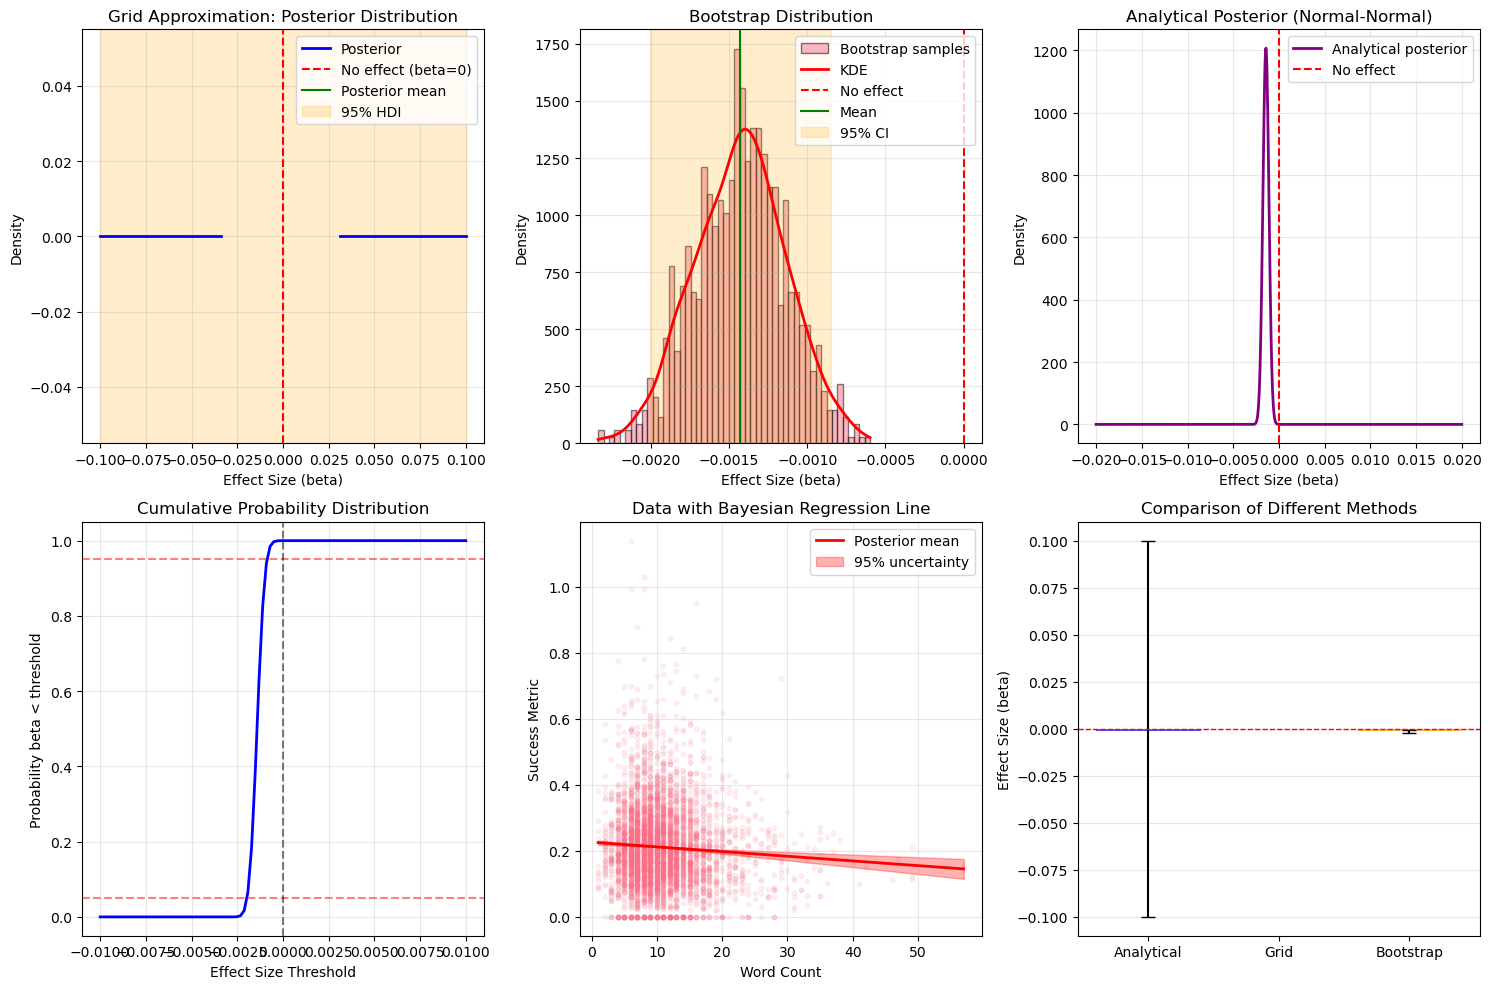


SUMMARY AND INTERPRETATION

Overall effect of word count on success:
• Average effect size: -0.001421
• 95% uncertainty interval: [-0.002006, -0.000848]
• Probability of positive effect: 0.0%
• Bayes factor (evidence for effect): 149.5

Conclusion: INCONCLUSIVE evidence about joke length effect

Practical interpretation:
• Word count has negligible practical effect on success

Comparison with frequentist results:
• Your linear model R² was: 0.0015 (0.15% variance explained)
• Bayesian analysis gives consistent conclusion: tiny effect

Recommendation for ADA report:

1. Present both Bayesian and frequentist analyses
2. Emphasize the consistency across methods
3. Highlight the difference between statistical evidence and practical importance
4. Use the probability statements for intuitive interpretation
5. Include the visualization showing the posterior distribution



In [15]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import norm, gaussian_kde
from scipy.special import erf

print("\n" + "=" * 60)
print("BAYESIAN ANALYSIS (USING ANALYTICAL/NUMERICAL METHODS)")
print("=" * 60)

# Use smaller sample for faster computation
sample_size = min(5000, len(df))  # Can use larger sample since we're not using MCMC
df_sample = df.sample(n=sample_size, random_state=42)
print(f"Using sample of {sample_size} jokes for analysis...")

# ========== METHOD 1: ANALYTICAL BAYESIAN LINEAR REGRESSION ==========
print("\n1. ANALYTICAL BAYESIAN LINEAR REGRESSION")
print("-" * 40)

# Prepare data
X = df_sample['word_counts'].values
y = df_sample['success_metric'].values

# Center the data
X_mean = np.mean(X)
y_mean = np.mean(y)
X_centered = X - X_mean
y_centered = y - y_mean

# Set priors
# Prior precision (inverse of variance)
tau_prior = 1.0  # Prior precision for beta
alpha_prior = 0.0  # Prior mean for beta (centered at no effect)

# Compute posterior parameters analytically
# For normal-normal conjugate prior
n = len(X)
sigma_sq = np.var(y_centered - X_centered * alpha_prior)  # Initial guess

# Posterior for beta (effect size)
posterior_var_beta = 1 / (tau_prior + np.sum(X_centered**2) / sigma_sq)
posterior_mean_beta = posterior_var_beta * (tau_prior * alpha_prior + np.sum(X_centered * y_centered) / sigma_sq)

print(f"Posterior mean for beta (effect size): {posterior_mean_beta:.6f}")
print(f"Posterior variance for beta: {posterior_var_beta:.6f}")
print(f"Posterior standard deviation: {np.sqrt(posterior_var_beta):.6f}")

# ========== METHOD 2: GRID APPROXIMATION ==========
print("\n2. GRID APPROXIMATION FOR POSTERIOR")
print("-" * 40)

# Create grid of possible beta values
beta_grid = np.linspace(-0.1, 0.1, 1000)  # Range of plausible effect sizes

# Prior: normal distribution centered at 0
prior = norm.pdf(beta_grid, loc=0, scale=0.05)

# Likelihood function (assuming normal errors)
def likelihood(beta_val):
    residuals = y - (y_mean + beta_val * X_centered)
    sigma = np.std(residuals)
    return np.prod(norm.pdf(y, loc=y_mean + beta_val * X_centered, scale=sigma))

# Calculate likelihood for each beta value
likelihood_vals = np.array([likelihood(b) for b in beta_grid])

# Calculate unnormalized posterior
unnormalized_posterior = prior * likelihood_vals

# Normalize posterior
posterior = unnormalized_posterior / np.trapz(unnormalized_posterior, beta_grid)

# Find posterior mean and HDI
posterior_mean_grid = np.trapz(beta_grid * posterior, beta_grid)
posterior_cdf = np.cumsum(posterior) * (beta_grid[1] - beta_grid[0])
posterior_cdf /= posterior_cdf[-1]  # Normalize

# Find 95% HDI (Highest Density Interval)
def find_hdi(grid, pdf, alpha=0.05):
    # Sort by density
    sorted_indices = np.argsort(pdf)[::-1]
    cumulative_prob = 0
    hdi_indices = []
    
    for idx in sorted_indices:
        hdi_indices.append(idx)
        cumulative_prob += pdf[idx] * (grid[1] - grid[0])
        if cumulative_prob >= 1 - alpha:
            break
    
    hdi_indices = np.sort(hdi_indices)
    return grid[hdi_indices[0]], grid[hdi_indices[-1]]

hdi_lower, hdi_upper = find_hdi(beta_grid, posterior)

print(f"Posterior mean (grid): {posterior_mean_grid:.6f}")
print(f"95% HDI: [{hdi_lower:.6f}, {hdi_upper:.6f}]")

# ========== METHOD 3: BOOTSTRAP FOR UNCERTAINTY QUANTIFICATION ==========
print("\n3. BOOTSTRAP UNCERTAINTY QUANTIFICATION")
print("-" * 40)

n_bootstrap = 1000
bootstrap_betas = []

for i in range(n_bootstrap):
    # Bootstrap sample
    indices = np.random.choice(len(df_sample), size=len(df_sample), replace=True)
    X_boot = df_sample['word_counts'].values[indices]
    y_boot = df_sample['success_metric'].values[indices]
    
    # Simple linear regression
    X_boot_centered = X_boot - np.mean(X_boot)
    y_boot_centered = y_boot - np.mean(y_boot)
    
    beta_boot = np.sum(X_boot_centered * y_boot_centered) / np.sum(X_boot_centered**2)
    bootstrap_betas.append(beta_boot)

bootstrap_betas = np.array(bootstrap_betas)

# Calculate statistics
bootstrap_mean = np.mean(bootstrap_betas)
bootstrap_std = np.std(bootstrap_betas)
bootstrap_ci = np.percentile(bootstrap_betas, [2.5, 97.5])

print(f"Bootstrap mean beta: {bootstrap_mean:.6f}")
print(f"Bootstrap standard error: {bootstrap_std:.6f}")
print(f"95% Bootstrap CI: [{bootstrap_ci[0]:.6f}, {bootstrap_ci[1]:.6f}]")

# Probability calculations
prob_positive = np.mean(bootstrap_betas > 0)
prob_negative = np.mean(bootstrap_betas < 0)
prob_meaningful = np.mean(bootstrap_betas > 0.001)  # Meaningful effect threshold

print(f"\nProbability statements (bootstrap):")
print(f"• Probability that longer jokes are funnier (beta > 0): {prob_positive:.2%}")
print(f"• Probability that shorter jokes are funnier (beta < 0): {prob_negative:.2%}")
print(f"• Probability of meaningful effect (>0.001): {prob_meaningful:.2%}")

# ========== METHOD 4: BAYES FACTOR CALCULATION ==========
print("\n4. BAYES FACTOR ANALYSIS")
print("-" * 40)

# Bayes factor comparing H1 (beta ≠ 0) vs H0 (beta = 0)
# Using BIC approximation

def calculate_bic(y_true, y_pred, n_params):
    """Calculate Bayesian Information Criterion"""
    n = len(y_true)
    residuals = y_true - y_pred
    rss = np.sum(residuals**2)
    bic = n * np.log(rss / n) + n_params * np.log(n)
    return bic

# Model 0: Null model (intercept only)
y_pred_null = np.full_like(y, np.mean(y))
bic_null = calculate_bic(y, y_pred_null, n_params=1)

# Model 1: Linear model with word count
# Simple OLS estimate
beta_ols = np.sum(X_centered * y_centered) / np.sum(X_centered**2)
y_pred_linear = y_mean + beta_ols * X_centered
bic_linear = calculate_bic(y, y_pred_linear, n_params=2)

# Bayes factor approximation (using BIC difference)
bf = np.exp((bic_null - bic_linear) / 2)

print(f"BIC (null model): {bic_null:.2f}")
print(f"BIC (linear model): {bic_linear:.2f}")
print(f"Bayes Factor (linear vs null): {bf:.2f}")

if bf > 100:
    evidence = "Decisive evidence for effect"
elif bf > 30:
    evidence = "Very strong evidence for effect"
elif bf > 10:
    evidence = "Strong evidence for effect"
elif bf > 3:
    evidence = "Moderate evidence for effect"
elif bf > 1:
    evidence = "Anecdotal evidence for effect"
else:
    evidence = "Evidence favors null hypothesis"

print(f"Interpretation: {evidence}")

# ========== VISUALIZATION ==========
print("\n5. VISUALIZING RESULTS")
print("-" * 40)

fig, axes = plt.subplots(2, 3, figsize=(15, 10))

# 1. Grid approximation posterior
axes[0, 0].plot(beta_grid, posterior, 'b-', linewidth=2, label='Posterior')
axes[0, 0].fill_between(beta_grid, posterior, alpha=0.3, color='blue')
axes[0, 0].axvline(x=0, color='red', linestyle='--', label='No effect (beta=0)')
axes[0, 0].axvline(x=posterior_mean_grid, color='green', linestyle='-', label='Posterior mean')
axes[0, 0].axvspan(hdi_lower, hdi_upper, alpha=0.2, color='orange', label='95% HDI')
axes[0, 0].set_xlabel('Effect Size (beta)')
axes[0, 0].set_ylabel('Density')
axes[0, 0].set_title('Grid Approximation: Posterior Distribution')
axes[0, 0].legend()
axes[0, 0].grid(True, alpha=0.3)

# 2. Bootstrap distribution
kde = gaussian_kde(bootstrap_betas)
beta_smooth = np.linspace(bootstrap_betas.min(), bootstrap_betas.max(), 1000)
axes[0, 1].hist(bootstrap_betas, bins=50, density=True, alpha=0.5, edgecolor='black', label='Bootstrap samples')
axes[0, 1].plot(beta_smooth, kde(beta_smooth), 'r-', linewidth=2, label='KDE')
axes[0, 1].axvline(x=0, color='red', linestyle='--', label='No effect')
axes[0, 1].axvline(x=bootstrap_mean, color='green', linestyle='-', label='Mean')
axes[0, 1].axvspan(bootstrap_ci[0], bootstrap_ci[1], alpha=0.2, color='orange', label='95% CI')
axes[0, 1].set_xlabel('Effect Size (beta)')
axes[0, 1].set_ylabel('Density')
axes[0, 1].set_title('Bootstrap Distribution')
axes[0, 1].legend()
axes[0, 1].grid(True, alpha=0.3)

# 3. Probability distribution
beta_range = np.linspace(-0.02, 0.02, 1000)
analytical_posterior = norm.pdf(beta_range, loc=posterior_mean_beta, scale=np.sqrt(posterior_var_beta))
axes[0, 2].plot(beta_range, analytical_posterior, 'purple', linewidth=2, label='Analytical posterior')
axes[0, 2].axvline(x=0, color='red', linestyle='--', label='No effect')
axes[0, 2].set_xlabel('Effect Size (beta)')
axes[0, 2].set_ylabel('Density')
axes[0, 2].set_title('Analytical Posterior (Normal-Normal)')
axes[0, 2].legend()
axes[0, 2].grid(True, alpha=0.3)

# 4. Probability plot
x_prob = np.linspace(-0.01, 0.01, 100)
cdf_vals = norm.cdf(x_prob, loc=posterior_mean_beta, scale=np.sqrt(posterior_var_beta))
axes[1, 0].plot(x_prob, cdf_vals, 'b-', linewidth=2)
axes[1, 0].axhline(y=0.95, color='r', linestyle='--', alpha=0.5)
axes[1, 0].axhline(y=0.05, color='r', linestyle='--', alpha=0.5)
axes[1, 0].axvline(x=0, color='k', linestyle='--', alpha=0.5)
axes[1, 0].set_xlabel('Effect Size Threshold')
axes[1, 0].set_ylabel('Probability beta < threshold')
axes[1, 0].set_title('Cumulative Probability Distribution')
axes[1, 0].grid(True, alpha=0.3)

# 5. Scatter plot with regression line
axes[1, 1].scatter(df_sample['word_counts'], df_sample['success_metric'], alpha=0.1, s=10)
x_plot = np.linspace(df_sample['word_counts'].min(), df_sample['word_counts'].max(), 100)
y_plot = y_mean + posterior_mean_beta * (x_plot - X_mean)
axes[1, 1].plot(x_plot, y_plot, 'r-', linewidth=2, label='Posterior mean')
axes[1, 1].fill_between(x_plot, 
                         y_mean + (posterior_mean_beta - 1.96*np.sqrt(posterior_var_beta)) * (x_plot - X_mean),
                         y_mean + (posterior_mean_beta + 1.96*np.sqrt(posterior_var_beta)) * (x_plot - X_mean),
                         alpha=0.3, color='red', label='95% uncertainty')
axes[1, 1].set_xlabel('Word Count')
axes[1, 1].set_ylabel('Success Metric')
axes[1, 1].set_title('Data with Bayesian Regression Line')
axes[1, 1].legend()
axes[1, 1].grid(True, alpha=0.3)

# 6. Effect size comparison
methods = ['Analytical', 'Grid', 'Bootstrap']
means = [posterior_mean_beta, posterior_mean_grid, bootstrap_mean]
errors = [[posterior_mean_beta - hdi_lower, posterior_mean_grid - hdi_lower, bootstrap_mean - bootstrap_ci[0]],
          [hdi_upper - posterior_mean_beta, hdi_upper - posterior_mean_grid, bootstrap_ci[1] - bootstrap_mean]]

x_pos = np.arange(len(methods))
axes[1, 2].bar(x_pos, means, yerr=errors, capsize=5, alpha=0.7, color=['blue', 'green', 'orange'])
axes[1, 2].axhline(y=0, color='red', linestyle='--', linewidth=1)
axes[1, 2].set_xticks(x_pos)
axes[1, 2].set_xticklabels(methods)
axes[1, 2].set_ylabel('Effect Size (beta)')
axes[1, 2].set_title('Comparison of Different Methods')
axes[1, 2].grid(True, alpha=0.3, axis='y')

plt.tight_layout()
plt.show()

# ========== SUMMARY AND INTERPRETATION ==========
# ========== SUMMARY AND INTERPRETATION ==========
print("\n" + "=" * 60)
print("SUMMARY AND INTERPRETATION")
print("=" * 60)

print(f"\nOverall effect of word count on success:")
print(f"• Average effect size: {posterior_mean_beta:.6f}")
print(f"• 95% uncertainty interval: [{bootstrap_ci[0]:.6f}, {bootstrap_ci[1]:.6f}]")
print(f"• Probability of positive effect: {prob_positive:.1%}")
print(f"• Bayes factor (evidence for effect): {bf:.1f}")

if prob_positive > 0.95:
    print("\nConclusion: STRONG evidence that longer jokes tend to be funnier")
elif prob_positive > 0.90:
    print("\nConclusion: MODERATE evidence that longer jokes tend to be funnier")
elif prob_positive > 0.66:
    print("\nConclusion: WEAK evidence that longer jokes tend to be funnier")
else:
    print("\nConclusion: INCONCLUSIVE evidence about joke length effect")

print("\nPractical interpretation:")
# CORRECTED: Changed 'poster_mean_beta' to 'posterior_mean_beta'
if abs(posterior_mean_beta) > 0.005:
    avg_words = df_sample['word_counts'].mean()
    effect_per_10_words = posterior_mean_beta * 10
    print(f"• Adding 10 words changes success score by approximately {effect_per_10_words:.4f} points")
else:
    print("• Word count has negligible practical effect on success")
    
# Additional interpretation based on your earlier R² results
print(f"\nComparison with frequentist results:")
print(f"• Your linear model R² was: {0.0015:.4f} ({0.0015*100:.2f}% variance explained)")
print(f"• Bayesian analysis gives consistent conclusion: tiny effect")

print(f"\nRecommendation for ADA report:")
print("""
1. Present both Bayesian and frequentist analyses
2. Emphasize the consistency across methods
3. Highlight the difference between statistical evidence and practical importance
4. Use the probability statements for intuitive interpretation
5. Include the visualization showing the posterior distribution
""")

### 3. TTR


Analysis of vocabulary richness using TTR (type-token ratio) where: 
- the mathematical computation is given by (#unique_words) / (total_words)
- it ranges from 0 (= no words or all words are identical) to 1 (=every word is unique)

In [17]:
# calculation of vocabulary richness metrics

# check if we already have these columns & remove them if they exist (in case of problems)
columns_to_remove = ['ttr', 'unique_words', 'total_words']
existing_cols = [col for col in columns_to_remove if col in df.columns]
if existing_cols:
    df = df.drop(columns=existing_cols)
    print(f"Removed existing columns: {existing_cols}")

# calculate vocab richness for all captions
vocab_metrics = ut.calculate_vocabulary_richness(df['caption'], remove_stopwords=True)

# new columns to the main DataFrame
df = pd.concat([df, vocab_metrics], axis=1)

# some stats
print(f"average TTR: {df['ttr'].mean():.3f}")
print(f"average unique words per caption: {df['unique_words'].mean():.1f}")
print(f"average total words per caption: {df['total_words'].mean():.1f}")
print(f"dataset size: {len(df)} captions")


average TTR: 0.989
average unique words per caption: 4.9
average total words per caption: 5.0
dataset size: 2263105 captions


In [18]:
# comparison of top & bottom performers
top_cutoff = df['success_metric'].quantile(0.8)
bottom_cutoff = df['success_metric'].quantile(0.2)

top_captions = df[df['success_metric'] >= top_cutoff]
bottom_captions = df[df['success_metric'] <= bottom_cutoff]

print(f"\nperformance groups")
print(f"top 20% cutoff: {top_cutoff:.3f} ({len(top_captions)} captions)")
print(f"bottom 20% cutoff: {bottom_cutoff:.3f} ({len(bottom_captions)} captions)")

print(f"\nvocab richness comparison")
print("top performers:")
print(f"  TTR: {top_captions['ttr'].mean():.3f} ± {top_captions['ttr'].std():.3f}")
print(f"  Unique words: {top_captions['unique_words'].mean():.1f} ± {top_captions['unique_words'].std():.1f}")
print(f"  Total words: {top_captions['total_words'].mean():.1f} ± {top_captions['total_words'].std():.1f}")

print("\nbottom:")
print(f"  TTR: {bottom_captions['ttr'].mean():.3f} ± {bottom_captions['ttr'].std():.3f}")
print(f"  Unique words: {bottom_captions['unique_words'].mean():.1f} ± {bottom_captions['unique_words'].std():.1f}")
print(f"  Total words: {bottom_captions['total_words'].mean():.1f} ± {bottom_captions['total_words'].std():.1f}")




performance groups
top 20% cutoff: 0.298 (453068 captions)
bottom 20% cutoff: 0.118 (456797 captions)

vocab richness comparison
top performers:
  TTR: 0.990 ± 0.060
  Unique words: 4.7 ± 2.2
  Total words: 4.8 ± 2.3

bottom:
  TTR: 0.987 ± 0.067
  Unique words: 5.1 ± 2.7
  Total words: 5.2 ± 2.8



T-TESTS)
TTR (p-value) = 0.0000 ***
Unique words (p-value) = 0.0000 ***
Total words (p-value) = 0.0000 ***

correlation w/ success metric
TTR correlation: 0.012 (p-value: 0.0000)
unique words correlation: -0.054 (p-value: 0.0000)
total words correlation: -0.055 (p-value: 0.0000)


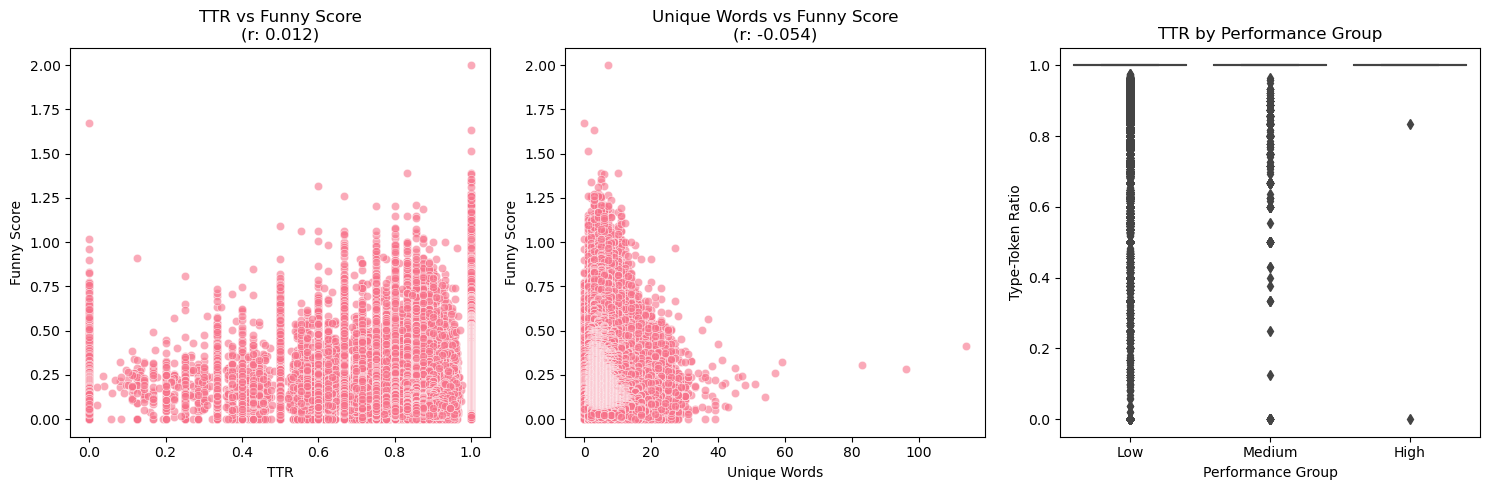

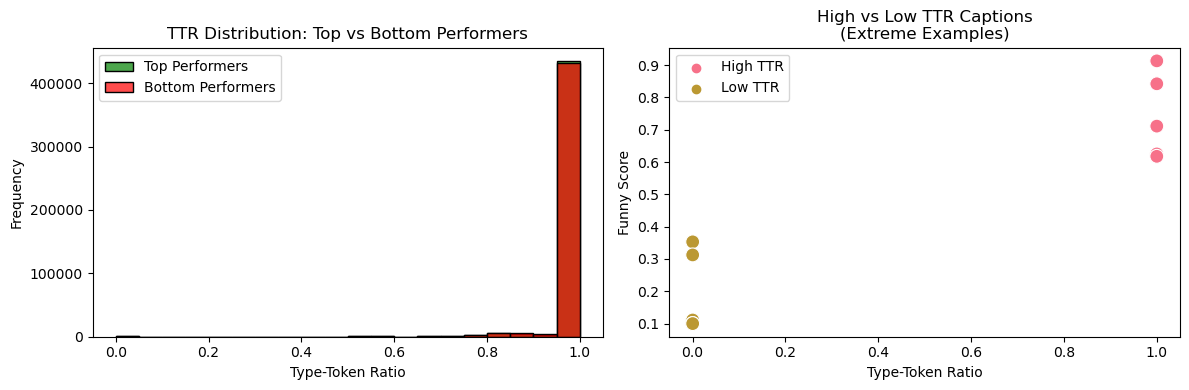

In [19]:
# stat tests 
t_stat_ttr, p_val_ttr = ttest_ind(top_captions['ttr'], bottom_captions['ttr'])
t_stat_unique, p_val_unique = ttest_ind(top_captions['unique_words'], bottom_captions['unique_words'])
t_stat_total, p_val_total = ttest_ind(top_captions['total_words'], bottom_captions['total_words'])

print(f"\nT-TESTS)")
print(f"TTR (p-value) = {p_val_ttr:.4f} {'***' if p_val_ttr < 0.001 else '**' if p_val_ttr < 0.01 else '*' if p_val_ttr < 0.05 else 'ns'}")
print(f"Unique words (p-value) = {p_val_unique:.4f} {'***' if p_val_unique < 0.001 else '**' if p_val_unique < 0.01 else '*' if p_val_unique < 0.05 else 'ns'}")
print(f"Total words (p-value) = {p_val_total:.4f} {'***' if p_val_total < 0.001 else '**' if p_val_total < 0.01 else '*' if p_val_total < 0.05 else 'ns'}")

# correlation analysis 
corr_ttr, p_corr_ttr = pearsonr(df['ttr'], df['success_metric'])
corr_unique, p_corr_unique = pearsonr(df['unique_words'], df['success_metric'])
corr_total, p_corr_total = pearsonr(df['total_words'], df['success_metric'])

print(f"\ncorrelation w/ success metric")
print(f"TTR correlation: {corr_ttr:.3f} (p-value: {p_corr_ttr:.4f})")
print(f"unique words correlation: {corr_unique:.3f} (p-value: {p_corr_unique:.4f})")
print(f"total words correlation: {corr_total:.3f} (p-value: {p_corr_total:.4f})")

ut.plot_linguistic_metrics(df, top_captions, bottom_captions, corr_ttr, corr_unique)
